# EN4554 Assignment on CNNs


Name : Peiris T.P.N.S

Index number : 220454P

## 1. Setup

Use CIFAR-10 (torchvision.datasets.CIFAR10): split the training set into 45k
train and 5k validation, normalize per channel with training statistics, and fix random seeds.



In [8]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import random_split, DataLoader, Subset
import numpy as np
import random

In [9]:
# Fix Random seeds for Reproducibility
def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

  set_seed(42)


In [10]:
raw_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)

# Split the training set into 45k train and 5k validation
generator = torch.Generator().manual_seed(42)
train_split, val_split = random_split(raw_dataset, [45000,5000],generator=generator)

# Calculate per-channel mean and std using only the training statistics
train_data = raw_dataset.data[train_split.indices] /255.0
mean_stats= train_data.mean(axis=(0,1,2))
std_stats = train_data.std(axis=(0,1,2))

print(f"Mean: {mean_stats} \nStd: {std_stats}")

# Normalize per channel with training statistics
base_transform = transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(mean=mean_stats.tolist(),std=std_stats.tolist())])

# Instantiate seperate datasets for train and val
full_train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,transform=base_transform)
full_val_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,transform=base_transform)

train_subset = Subset(full_train_dataset, train_split.indices)
val_subset = Subset(full_val_dataset, val_split.indices)

train_loader= DataLoader(train_subset, batch_size=128, shuffle=True,num_workers=2)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False, num_workers=2)

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=base_transform)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)






Mean: [0.49165571 0.48233405 0.44667923] 
Std: [0.24708116 0.24350869 0.26158066]


## 2. Backpropagation

a. Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward (no autograd), and
assemble an MLP.

In [11]:
import torch.nn.functional as F

class Linear:
  def __init__(self, in_features, out_features, seed=42):
    torch.manual_seed(seed)
    # Kaiming initialization
    self.W = torch.randn(in_features, out_features) * (2.0/in_features)**0.5
    self.b = torch.zeros(out_features)

    self.X = None
    self.grad_W = None
    self.grad_b = None

  def forward(self,X):
    self.X = X
    return X @ self.W + self.b

  def backward(self, dZ):
    self.grad_W = self.X.T @ dZ
    self.grad_b = dZ.sum(dim=0)
    dX = dZ @ self.W.T
    return dX





In [12]:
class ReLU:
  def __init__(self):
    self.mask = None

  def forward(self,Z):
    self.mask = (Z>0).float()
    return Z*self.mask

  def backward(self,dA):
    return dA*self.mask

In [14]:
class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.targets = None

    def forward(self, logits, targets):
        # targets: (batch_size,) integer labels
        self.targets = targets

        # Shift logits for numerical stability
        logits_max = torch.max(logits, dim=1, keepdim=True).values
        exp_logits = torch.exp(logits - logits_max)
        self.probs = exp_logits / torch.sum(exp_logits, dim=1, keepdim=True)

        batch_size = logits.size(0)
        core_probs = self.probs[torch.arange(batch_size), targets]
        loss = -torch.log(core_probs + 1e-9).mean()
        return loss

    def backward(self):
        batch_size = self.probs.size(0)
        dZ = self.probs.clone()
        dZ[torch.arange(batch_size), self.targets] -= 1.0
        dZ = dZ /batch_size
        return dZ

In [28]:
class CustomMLP:
  def __init__(self, in_dim=3072, hidden_dim=256, out_dim=10):
    self.fc1 = Linear(in_dim, hidden_dim)
    self.relu = ReLU()
    self.fc2 = Linear(hidden_dim, out_dim)
    self.criterion = SoftmaxCrossEntropy()

  def forward(self,X):
    Z1 = self.fc1.forward(X)
    A1 = self.relu.forward(Z1)
    logits = self.fc2.forward(A1)
    return logits

  def backward(self):
    d_logits = self.criterion.backward()
    d_A1 = self.fc2.backward(d_logits)
    d_Z1 = self.relu.backward(d_A1)
    self.fc1.backward(d_Z1)

b. Verify your gradients against autograd and against centred finite differences; report the relative errors. Use
torch.allclose to check whether the gradients match

In [22]:
def check_gradients():
    torch.manual_seed(42)
    X = torch.randn(4, 10, dtype=torch.float64) # Use float64 for finite differences precision
    y = torch.randint(0, 5, (4,))

    # 1. Custom Setup
    linear = Linear(10, 5)
    linear.W = linear.W.to(torch.float64)
    linear.b = linear.b.to(torch.float64)
    criterion = SoftmaxCrossEntropy()

    # Forward and manual backward
    logits_custom = linear.forward(X)
    loss_custom = criterion.forward(logits_custom, y)
    dZ = criterion.backward()
    linear.backward(dZ)
    grad_W_custom = linear.grad_W.clone()

    # 2. Autograd Setup
    W_auto = linear.W.clone().requires_grad_(True)
    b_auto = linear.b.clone().requires_grad_(True)

    logits_auto = X @ W_auto + b_auto
    loss_auto = F.cross_entropy(logits_auto, y)
    loss_auto.backward()
    grad_W_auto = W_auto.grad.clone()

    # 3. Finite Differences Setup
    epsilon = 1e-5
    grad_W_fd = torch.zeros_like(linear.W)

    for i in range(linear.W.size(0)):
        for j in range(linear.W.size(1)):
            W_plus = linear.W.clone()
            W_plus[i, j] += epsilon
            loss_plus = criterion.forward(X @ W_plus + linear.b, y)

            W_minus = linear.W.clone()
            W_minus[i, j] -= epsilon
            loss_minus = criterion.forward(X @ W_minus + linear.b, y)

            grad_W_fd[i, j] = (loss_plus - loss_minus) / (2 * epsilon)

    # Reporting
    rel_error_auto = torch.norm(grad_W_custom - grad_W_auto) / torch.norm(grad_W_auto)
    rel_error_fd = torch.norm(grad_W_custom - grad_W_fd) / torch.norm(grad_W_fd)

    match_auto = torch.allclose(grad_W_custom, grad_W_auto, atol=1e-5)
    match_fd = torch.allclose(grad_W_custom, grad_W_fd, atol=1e-5)

    print(f"Match Autograd: {match_auto}, Relative Error: {rel_error_auto.item():.2e}")
    print(f"Match Finite Diff: {match_fd}, Relative Error: {rel_error_fd.item():.2e}")

check_gradients()

Match Autograd: True, Relative Error: 8.41e-17
Match Finite Diff: True, Relative Error: 3.29e-08


c. Train it with SGD on flattened CIFAR-10 images; plot the loss and report validation accuracy.

Epoch [1/10] | Training Loss: 1.8674
Epoch [2/10] | Training Loss: 1.5368
Epoch [3/10] | Training Loss: 1.4586
Epoch [4/10] | Training Loss: 1.4007
Epoch [5/10] | Training Loss: 1.3523
Epoch [6/10] | Training Loss: 1.3258
Epoch [7/10] | Training Loss: 1.2772
Epoch [8/10] | Training Loss: 1.2713
Epoch [9/10] | Training Loss: 1.2264
Epoch [10/10] | Training Loss: 1.2053


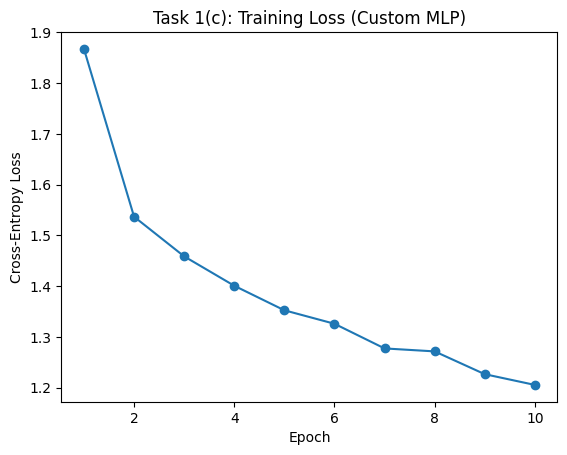

Final Validation Accuracy: 45.16%


In [30]:
import matplotlib.pyplot as plt

def train_custom_mlp(train_loader, val_loader, epochs=10, lr = 0.1):
  model = CustomMLP(in_dim=3072,hidden_dim=256,out_dim=10)
  train_losses = []

  for epoch in range(epochs):
    epoch_loss = 0.0

    # Training loop
    for images, labels in train_loader:
      X = images.view(images.size(0), -1)

      # Forward pass
      logits = model.forward(X)
      loss = model.criterion.forward(logits, labels)
      epoch_loss += loss.item()

      # Backward pass
      model.backward()

      # SGD step
      model.fc1.W -= lr * model.fc1.grad_W
      model.fc1.b -= lr * model.fc1.grad_b
      model.fc2.W -= lr * model.fc2.grad_W
      model.fc2.b -= lr * model.fc2.grad_b

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}] | Training Loss: {avg_loss:.4f}")

  correct = 0
  total = 0
  for images, labels in val_loader:
    X = images.view(images.size(0), -1)
    logits = model.forward(X)
    predictions = torch.argmax(logits, dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

  val_acc = 100 * correct / total

  plt.plot(range(1, epochs+1), train_losses, marker='o')
  plt.title("Task 1(c): Training Loss (Custom MLP)")
  plt.xlabel("Epoch")
  plt.ylabel("Cross-Entropy Loss")
  plt.show()

  print(f"Final Validation Accuracy: {val_acc:.2f}%")

train_custom_mlp(train_loader, val_loader, epochs=10, lr=0.1)

d. For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.

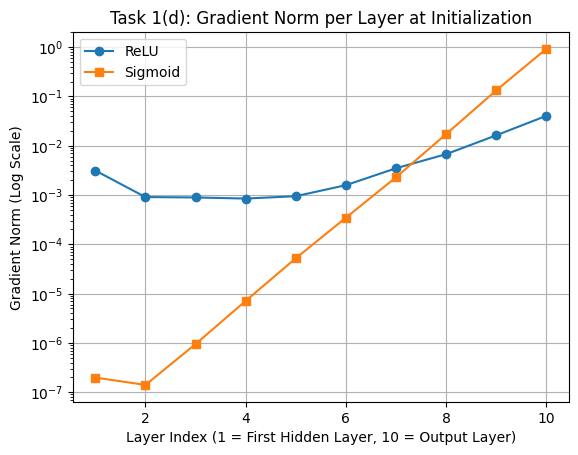

In [36]:
import torch.nn as nn
import matplotlib.pyplot as plt

def analyze_gradients():
  def build_10_layer_mlp(activation):
    layers = []
    in_dim = 3072
    for _ in range(9):
      layers.append(nn.Linear(in_dim,256))
      layers.append(activation)
      in_dim = 256
    layers.append(nn.Linear(in_dim,10))
    return nn.Sequential(*layers)

  torch.manual_seed(42)
  relu_model = build_10_layer_mlp(nn.ReLU())
  sigmoid_model = build_10_layer_mlp(nn.Sigmoid())

  X = torch.randn(32,3072)
  y = torch.randint(0,10,(32,))
  criterion = nn.CrossEntropyLoss()

  criterion(relu_model(X),y).backward()
  criterion(sigmoid_model(X),y).backward()

  relu_norms = [layer.weight.grad.norm().item() for layer in relu_model if isinstance(layer, nn.Linear)]
  sigmoid_norms = [layer.weight.grad.norm().item() for layer in sigmoid_model if isinstance(layer, nn.Linear)]

  layer_indices = list(range(1, 11))
  plt.plot(layer_indices, relu_norms, label='ReLU', marker='o')
  plt.plot(layer_indices, sigmoid_norms, label='Sigmoid', marker='s')
  plt.yscale('log')
  plt.title("Task 1(d): Gradient Norm per Layer at Initialization")
  plt.xlabel("Layer Index (1 = First Hidden Layer, 10 = Output Layer)")
  plt.ylabel("Gradient Norm (Log Scale)")
  plt.legend()
  plt.grid(True)
  plt.show()

analyze_gradients()